# 03 - Train U-Net + MaxViT-base (issue #20)

**Why.** MaxViT is the primary source model: a transformer encoder that sees the whole chip at once, where the ResNet50 baseline (#19) looks through small windows. Its checkpoint is what the NISAR transfer experiments start from.

**What.** The same training script and config as the CNN arm (`configs/unet_resnet50.yaml`), with three deliberate differences, all recorded in `configs/unet_maxvit.yaml`:
- encoder `maxvit_base` instead of `resnet50`
- `batch_size: 4` with `accum_steps: 2`, an effective batch of 8 like the ResNet run, because batch 8 does not fit on a T4 (trial run: out of memory)
- the output folder

**How.** Run the sections in order on a **T4 GPU** runtime (Runtime -> Change runtime type). Expect about 1.5-2 hours for the full run. If the session disconnects, rerun sections 1-3 and then the resume cell.

## 1. Code and packages

In [1]:
BRANCH = "20-train-maxvit-source-model"   # change to "main" once the PR has been merged

%cd /content
!rm -rf nisar-flood-mapping
!git clone -b {BRANCH} https://github.com/cs59300-deep-learning/nisar-flood-mapping.git
%cd nisar-flood-mapping
!git --no-pager log --oneline -3
!pip install -q segmentation-models-pytorch timm rasterio pyyaml tqdm matplotlib requests
!nvidia-smi | head -12

/content
Cloning into 'nisar-flood-mapping'...
remote: Enumerating objects: 1397, done.
remote: Counting objects: 100% (691/691), done.
remote: Compressing objects: 100% (393/393), done.
remote: Total 1397 (delta 391), reused 486 (delta 278), pack-reused 706 (from 1)
Receiving objects: 100% (1397/1397), 55.04 MiB | 28.45 MiB/s, done.
Resolving deltas: 100% (716/716), done.
/content/nisar-flood-mapping
ccd4643 (HEAD -> 20-train-maxvit-source-model, origin/20-train-maxvit-source-model) docs(notebooks): add MaxViT-base training notebook (#20)
e5f4676 feat(configs): add MaxViT-base config, batch 4 x accumulation 2 (#20)
d9a5ede feat(configs): add MaxViT-base config, batch 4 x accumulation 2 (#20)
Mon Nov 23 19:10:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+--------------

## 2. Data (Sen1Floods11 hand-labelled split, about 700 MB, about 4 minutes)

In [2]:
!PYTHONPATH=src python -m nisar_flood.datasets.sen1floods11 download
!PYTHONPATH=src python -m nisar_flood.datasets.sen1floods11 check

train: 100% 252/252 [05:38<00:00,  1.34s/it]
val: 100% 89/89 [01:41<00:00,  1.14s/it]
test: 100% 90/90 [01:38<00:00,  1.09s/it]
bolivia: 100% 15/15 [00:16<00:00,  1.11s/it]
OK    train    n=252 (expected 252) missing=0 water=9.5%
OK    val      n= 89 (expected 89) missing=0 water=11.0%
OK    test     n= 90 (expected 90) missing=0 water=12.5%
OK    bolivia  n= 15 (expected 15) missing=0 water=15.9%


## 3. Output folder on Google Drive

Colab's disk is wiped when a session ends, so the run writes to Drive. The checkpoint is large (about 1.5 GB), so it is saved every 10 epochs (`save_every`), which changes how often it is written, not the training itself. A temporary copy of the config is used so the repo file stays unchanged.

In [3]:
from google.colab import drive
import os, yaml
drive.mount('/content/drive')

OUT = '/content/drive/MyDrive/nisar_runs/unet_maxvit'
os.makedirs(OUT, exist_ok=True)

cfg = yaml.safe_load(open('configs/unet_maxvit.yaml'))
cfg['output']['dir'] = OUT
cfg['train']['save_every'] = 10
yaml.safe_dump(cfg, open('/content/run_maxvit.yaml', 'w'))
print(cfg['data'], cfg['train'], cfg['output'], sep='\n')

Mounted at /content/drive
{'root': 'data/sen1floods11', 'batch_size': 4, 'workers': 2, 'augment': True}
{'epochs': 100, 'lr': 0.0003, 'weight_decay': 0.0001, 'dice_weight': 1.0, 'amp': True, 'grad_clip': 1.0, 'scheduler': 'cosine', 'warmup_epochs': 2, 'seed': 0, 'accum_steps': 2, 'save_every': 10}
{'dir': '/content/drive/MyDrive/nisar_runs/unet_maxvit'}


## 4. Smoke test (optional, about 6 minutes)

Checks gradient accumulation and `--resume` before the long run: train 3 epochs with a throwaway seed, stop the cell once the `epoch 2/3` bar appears (the epoch-1 checkpoint is saved by then), then resume. The history should list epochs 1, 2, 3 once each. This writes to the local disk, not to Drive.

In [ ]:
!PYTHONPATH=src python -m nisar_flood.training.train --config configs/unet_maxvit.yaml --epochs 3 --seed 99

In [ ]:
!PYTHONPATH=src python -m nisar_flood.training.train --config configs/unet_maxvit.yaml --epochs 3 --seed 99 --resume
!cut -d, -f1-4 runs/unet_maxvit/seed99/history.csv

## 5. Full run (100 epochs, seed 0)

In [4]:
!PYTHONPATH=src python -m nisar_flood.training.train --config /content/run_maxvit.yaml

/usr/local/lib/python3.13/dist-packages/segmentation_models_pytorch/encoders/__init__.py:86: UserWarning: For 'tu-' (timm universal) encoders, `encoder_weights` should be set to True to download pretrained weights or None for random initialization. The pretrained variant is defined in the encoder name i.e 'tu-<model_name>.<pretrained_tag>'. Got encoder_weights='imagenet'.
  warnings.warn(

model.safetensors: downloading bytes:  53% 255M/480M [00:03<00:01, 164MB/s, 21.3MB/s  ]
model.safetensors: downloading bytes:  92% 443M/480M [00:06<00:00, 115MB/s, 31.6MB/s  ]
model.safetensors: reconstructing file:  70% 335M/480M [00:07<00:03, 43.9MB/s, 24.1MB/s  ]
model.safetensors: downloading bytes: 100% 456M/456M [00:07<00:00, 62.5MB/s, 33.4MB/s  ]
model.safetensors: reconstructing file: 100% 480M/480M [00:07<00:00, 65.8MB/s, 36.4MB/s  ]
unet_maxvit | cuda | float16 | 122,643,414 trainable params | seed 0
batch 4 x accumulation 2 = effective batch 8
train 252 chips, val 89 chips
  epoch   1  tra

**If the session disconnects:** rerun sections 1-3, then run this cell. It continues from the last saved epoch (at most 10 epochs are lost). It refuses to resume if the config differs from the one stored in the checkpoint.

In [ ]:
#!PYTHONPATH=src python -m nisar_flood.training.train --config /content/run_maxvit.yaml --resume

## 6. Results

{'name': 'unet_maxvit', 'seed': 0, 'best_epoch': 46, 'best_iou_water_per_chip_mean': 0.4518891297981577, 'minutes': 125.7, 'device': 'cuda'}
98,6.931330576202654e-07,0.2914462283490196,0.6578629407822416,0.6568354924935496,0.952297105088297,0.8045662987909232,0.4390789167512099,80,0.8301121927824876,0.7588434956124964,0.7928795531836506
99,3.081910874495497e-07,0.30171023746804587,0.6673697678560622,0.6489769401108096,0.9514943636656115,0.8002356518882106,0.43633362685628574,80,0.832520771784766,0.74642709504135,0.7871267624484779
100,7.706756989681596e-08,0.2992871869651098,0.6596556764640166,0.6579461108445148,0.9528006453557866,0.8053733781001506,0.43916093006658646,80,0.8366749830230426,0.7549026749582701,0.793688174230674


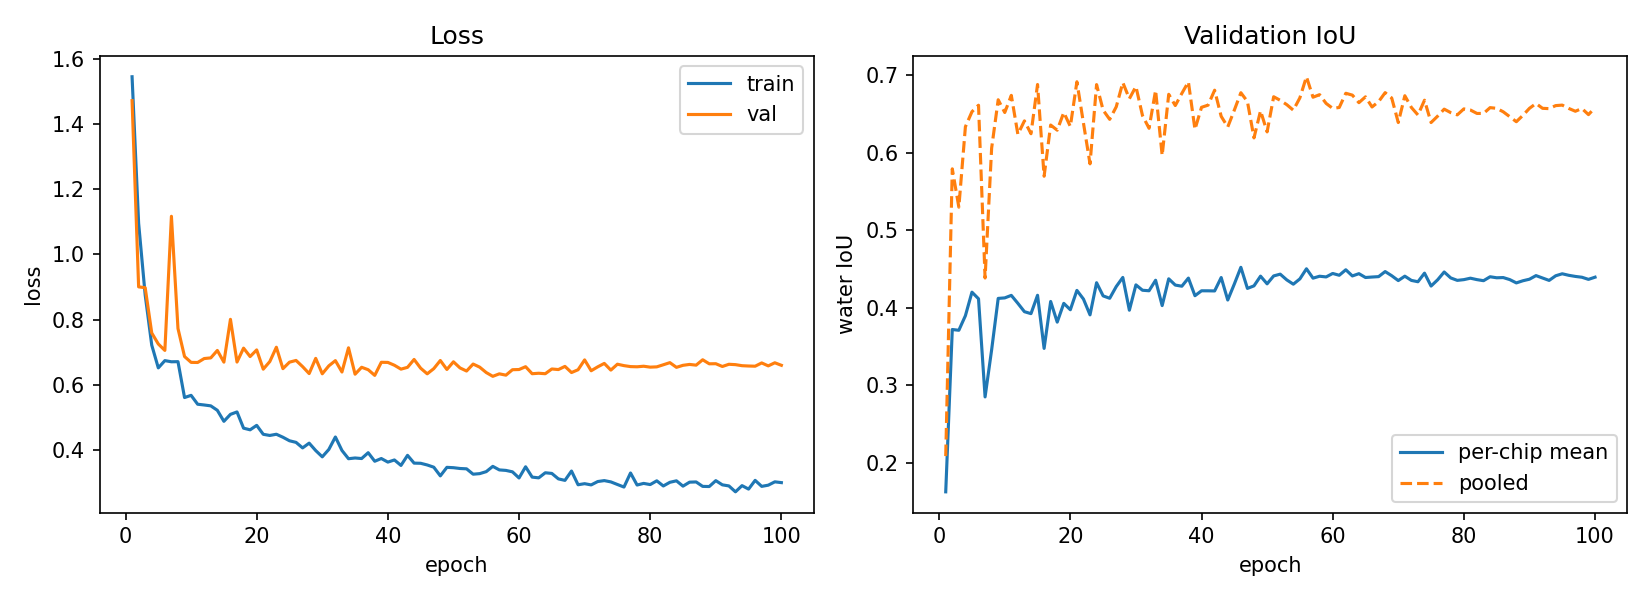

In [5]:
import json
s = json.load(open(f'{OUT}/seed0/summary.json'))
print({k: v for k, v in s.items() if k != 'config'})
!tail -n 3 {OUT}/seed0/history.csv
from IPython.display import Image
Image(f'{OUT}/seed0/curves.png')

Test and Bolivia scores use the evaluation entry point from #19. This cell has not yet been run for the MaxViT checkpoint, so check its output before reporting numbers.

In [6]:
!PYTHONPATH=src python -m nisar_flood.cli evaluate --checkpoint {OUT}/seed0/best.pt

/usr/local/lib/python3.13/dist-packages/segmentation_models_pytorch/encoders/__init__.py:86: UserWarning: For 'tu-' (timm universal) encoders, `encoder_weights` should be set to True to download pretrained weights or None for random initialization. The pretrained variant is defined in the encoder name i.e 'tu-<model_name>.<pretrained_tag>'. Got encoder_weights='imagenet'.
  warnings.warn(
unet_maxvit | checkpoint epoch 46 | seed 0 | cuda

test:
  iou_water_per_chip_mean    0.4434
  iou_water                  0.6898
  iou_not_water              0.9524
  miou                       0.8211
  precision                  0.8742
  recall                     0.7658
  f1                         0.8164
  n_chips_scored             85

bolivia:
  iou_water_per_chip_mean    0.4503
  iou_water                  0.7031
  iou_not_water              0.9364
  miou                       0.8198
  precision                  0.8264
  recall                     0.8249
  f1                         0.8257
  n_c

In [7]:
from google.colab import userdata
from huggingface_hub import HfApi
from pathlib import Path

checkpoint = Path(OUT) / "seed0" / "best.pt"
assert checkpoint.is_file(), f"Checkpoint not found: {checkpoint}"

token = userdata.get("HF_TOKEN")
assert token, "HF_TOKEN is missing from Colab Secrets or Notebook access is off."

api = HfApi(token=token)
api.upload_file(
    path_or_fileobj=str(checkpoint),
    path_in_repo="seed0/best.pt",
    repo_id="nisar-flood-mapping/unet-maxvit-sen1floods11",
    repo_type="model",
    commit_message="Add seed 0 U-Net MaxViT checkpoint",
)
print("Upload complete: seed0/best.pt")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...unet_maxvit/seed0/best.pt:   0%|          |  553kB /  492MB            

Validating                    :           |   0%            

Upload complete: seed0/best.pt
